<a href="https://colab.research.google.com/github/anishkumarcs24/BIS/blob/main/1BF24CS053_Week2_BIS/TSP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration  20 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration  40 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration  60 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration  80 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration 100 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration 120 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration 140 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration 160 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration 180 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration 200 | Iteration best = 306.56 | Best-so-far = 306.56

========== ACS TSP RESULTS ==========
Number of cities: 10
Number of ants: 10
Iterations: 200
Nearest-neighbour initial tour length: 351.19
Best route (city numbers): [6, 4, 1, 3, 2, 5, 7, 10, 8, 9, 6]
Best tour length: 306.56


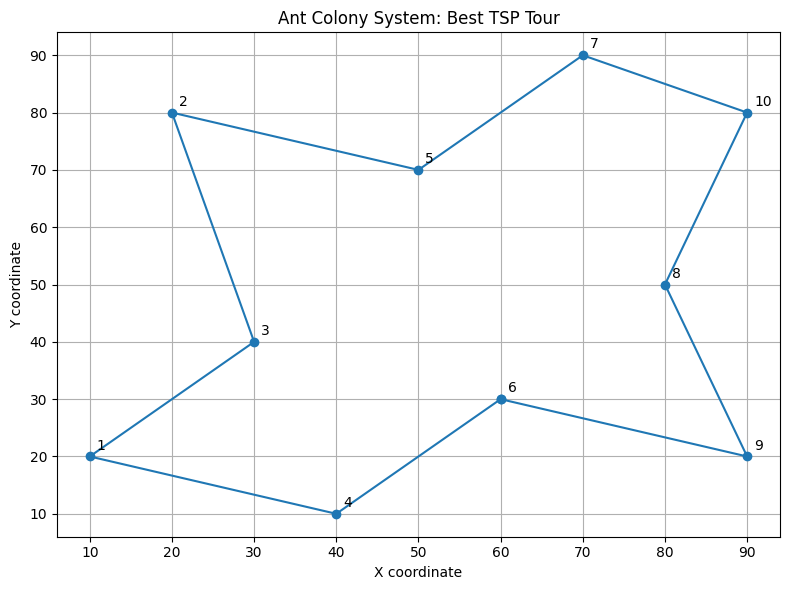

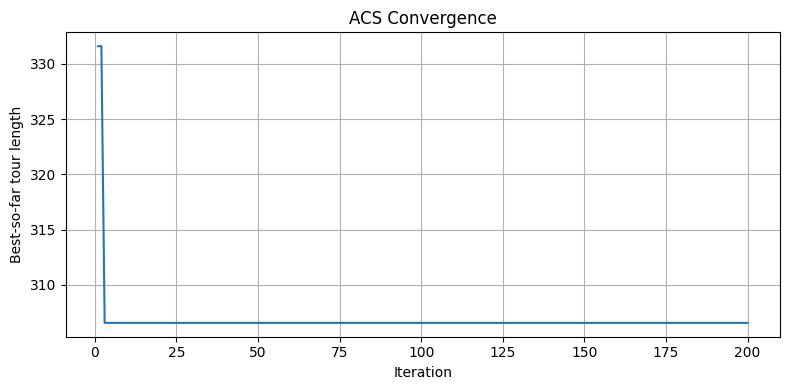

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# 1. Define the cities (x, y coordinates)
cities = np.array([
    [10, 20],
    [20, 80],
    [30, 40],
    [40, 10],
    [50, 70],
    [60, 30],
    [70, 90],
    [80, 50],
    [90, 20],
    [90, 80]
], dtype=float)

N = len(cities)

# 2. Calculate the symmetric distance matrix
distance = np.linalg.norm(
    cities[:, np.newaxis, :] - cities[np.newaxis, :, :],
    axis=2
)

# Heuristic desirability: shorter edges are preferred
visibility = np.zeros_like(distance)
mask = distance > 0
visibility[mask] = 1.0 / distance[mask]

# 3. ACS parameters
NUM_ANTS = N
ITERATIONS = 200

BETA = 2.0       # Importance of distance heuristic
Q0 = 0.9         # Probability of greedy exploitation
RHO = 0.1        # Local pheromone update coefficient
ALPHA = 0.1      # Global pheromone update coefficient

# 4. Initialize pheromone using a nearest-neighbour tour length
def nearest_neighbor_length(start=0):
    unvisited = set(range(N))
    unvisited.remove(start)
    current = start
    total = 0.0

    while unvisited:
        next_city = min(
            unvisited,
            key=lambda city: distance[current, city]
        )
        total += distance[current, next_city]
        unvisited.remove(next_city)
        current = next_city

    total += distance[current, start]
    return total


L_nn = nearest_neighbor_length()
tau0 = 1.0 / (N * L_nn)

pheromone = np.full((N, N), tau0)
np.fill_diagonal(pheromone, 0.0)

best_route = None
best_length = float("inf")
history = []

# 5. Main ACS iterations
for iteration in range(ITERATIONS):

    iteration_best_route = None
    iteration_best_length = float("inf")

    # Each ant constructs a complete tour
    for ant in range(NUM_ANTS):

        start = np.random.randint(N)
        route = [start]
        unvisited = set(range(N))
        unvisited.remove(start)

        # Construct the tour city by city
        while unvisited:
            current = route[-1]
            candidates = np.array(sorted(unvisited), dtype=int)

            # ACS transition rule:
            # desirability = pheromone * (1 / distance)^beta
            desirability = (
                pheromone[current, candidates]
                * visibility[current, candidates] ** BETA
            )

            # q <= q0: exploit the best edge
            # otherwise: probabilistically explore
            if np.random.random() <= Q0:
                next_city = candidates[np.argmax(desirability)]
            else:
                probabilities = desirability / desirability.sum()
                next_city = np.random.choice(
                    candidates, p=probabilities
                )

            route.append(int(next_city))
            unvisited.remove(int(next_city))

            # Local pheromone update immediately after using an edge
            pheromone[current, next_city] = (
                (1 - RHO) * pheromone[current, next_city]
                + RHO * tau0
            )
            pheromone[next_city, current] = (
                pheromone[current, next_city]
            )

        # Return to the starting city and locally update that edge
        route.append(start)
        current = route[-2]

        pheromone[current, start] = (
            (1 - RHO) * pheromone[current, start]
            + RHO * tau0
        )
        pheromone[start, current] = pheromone[current, start]

        # Calculate total tour length
        length = sum(
            distance[route[i], route[i + 1]]
            for i in range(N)
        )

        if length < iteration_best_length:
            iteration_best_length = length
            iteration_best_route = route.copy()

        if length < best_length:
            best_length = length
            best_route = route.copy()

    # 6. Global pheromone update on the best-so-far tour
    # Edges not belonging to this tour are left unchanged.
    for i in range(N):
        a = best_route[i]
        b = best_route[i + 1]

        updated = (
            (1 - ALPHA) * pheromone[a, b]
            + ALPHA / best_length
        )

        pheromone[a, b] = updated
        pheromone[b, a] = updated

    history.append(best_length)

    if (iteration + 1) % 20 == 0:
        print(
            f"Iteration {iteration + 1:3d} | "
            f"Iteration best = {iteration_best_length:.2f} | "
            f"Best-so-far = {best_length:.2f}"
        )

# 7. Print the final results
print("\n========== ACS TSP RESULTS ==========")
print("Number of cities:", N)
print("Number of ants:", NUM_ANTS)
print("Iterations:", ITERATIONS)
print("Nearest-neighbour initial tour length:", round(L_nn, 2))
print("Best route (city numbers):",
      [city + 1 for city in best_route])
print("Best tour length:", round(best_length, 2))
print("=====================================")

# 8. Visualize the best tour
route_coordinates = cities[best_route]

plt.figure(figsize=(8, 6))
plt.plot(
    route_coordinates[:, 0],
    route_coordinates[:, 1],
    "o-"
)

for i, (x, y) in enumerate(cities):
    plt.annotate(
        str(i + 1),
        (x, y),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Ant Colony System: Best TSP Tour")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.tight_layout()
plt.show()

# 9. Visualize convergence
plt.figure(figsize=(8, 4))
plt.plot(
    range(1, ITERATIONS + 1),
    history
)
plt.title("ACS Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best-so-far tour length")
plt.grid(True)
plt.tight_layout()
plt.show()